In [7]:
%pip install scikit-learn pandas numpy


   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 832.3 kB/s eta 0:00:10
   -- ------------------------------------- 0.5/8.4 MB 832.3 kB/s eta 0:00:10
   --- ------------------------------------ 0.8/8.4 MB 649.6 kB/s eta 0:00:12
   --- ------------------------------------ 0.8/8.4 MB 649.6 kB/s eta 0:00:12
   ----- ---------------------------------- 1.0/8.4 MB 615.7 kB/s eta 0:00:12
   ----- ---------------------------------- 1.0/8.4 MB 615.7 kB/s eta 0:00:12
   ------ --------------------------------- 1.3/8.4 MB 659.7 kB/s eta 0:00:11
   ------- -------------------------------- 1.6/8.4 MB 693.5 kB/s eta 0:00:10
   ------- -------------------------------- 1.6/8.4 MB 693.5 kB/s eta 0:00:10
   ------- -----------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import os

print(os.getcwd())
print(os.listdir())


c:\Users\Nani\Documents\mllab
['lab2.ipynb']


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV

# Load the dataset
df = pd.read_csv(r"C:\Users\Nani\Documents\lab_ticket_resolution (2).csv")

# Display the first five rows
display(df.head())

# Display dataset shape
print("Dataset shape:", df.shape)

# Display column data types
print("\nData types:")
print(df.dtypes)

# Display descriptive statistics
print("\nDescriptive statistics:")
display(df.describe(include="all"))

# Check missing values
print("\nMissing values:")
print(df.isna().sum())

,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


Dataset shape: (240, 6)

Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240,240.000000,240.000000,240.000000,240.000000,240.000000
unique,240,NaN,NaN,NaN,NaN,NaN
top,T0001,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,5.491667,54.820833,6.105417,0.233333,19.361125
std,NaN,2.979697,26.145017,3.391426,0.423836,10.035058
min,NaN,1.000000,1.000000,0.500000,0.000000,0.500000
25%,NaN,3.000000,33.000000,3.300000,0.000000,11.015000
50%,NaN,5.500000,54.000000,5.800000,0.000000,19.610000
75%,NaN,8.000000,74.000000,9.200000,0.000000,27.122500



Missing values:
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64


In [11]:
# Select the target we want to predict
y = df["resolution_hours"]

# Select the input features
X = df.drop(columns=[
    "resolution_hours",
    "ticket_id",
    "lines_changed",
    "reopened"
])

# Display the selected features
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   complexity_score  team_experience_years
0                 6                    5.6
1                 9                   11.5
2                 6                    3.3
3                 5                    9.6
4                 3                    6.4

Target:
0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64


The target variable (y) is resolution_hours because the goal is to predict how many hours a software support ticket takes to resolve.
The input features (X) are complexity_score and team_experience_years
The ticket_id column must be excluded since it doesnot give meaning ful predictive information
 The lines_changed and reopened columns are excluded because they may only become available after the ticket has been worked on or resolved

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (192, 2)
Testing data: (48, 2)


The training set is to train the machine learning and the test set sees how well they predict unseen data

In [13]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


# Fit the mean baseline
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_results = evaluate_model(baseline, X_test, y_test)

print("Mean Baseline Results:")
print(baseline_results)

Mean Baseline Results:
{'MAE': 9.113951822916667, 'RMSE': np.float64(10.597684800766308), 'R2': -0.021016765260001957}


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_baseline)

rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))

r2 = r2_score(y_test, y_pred_baseline)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²:", round(r2, 3))

MAE: 9.114
RMSE: 10.598
R²: -0.021


In [ ]:
import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the four models
models = {
    "Dummy Regression": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Polynomial Degree 2": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),

    "Polynomial Degree 3": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
}

# Store the evaluation results
results = []

# Train and evaluate each model
for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict using test data
    y_pred = model.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Save results
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Display results, sorted by MAE
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="MAE")

display(results_df.round(3))

,Model,MAE,RMSE,R2
1,Linear Regression,2.906,3.572,0.884
2,Polynomial Degree 2,3.020,3.741,0.873
3,Polynomial Degree 3,3.140,3.949,0.858
0,Dummy Regression,9.114,10.598,-0.021


In [6]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Nani\Documents\lab_ticket_resolution (2).csv")
# Check that the dataset loaded correctly
print(df.shape)
display(df.head())

(240, 6)


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


In [7]:
from sklearn.model_selection import train_test_split

# Input features available when making the prediction
X = df[["complexity_score", "team_experience_years"]]

# Value we want to predict
y = df["resolution_hours"]

# Split into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (192, 2)
Testing features: (48, 2)
Training target: (192,)
Testing target: (48,)


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

# Ridge regression
ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge()
)

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"ridge__alpha": alphas},
    cv=cv,
    scoring="neg_mean_absolute_error"
)

ridge_search.fit(X_train, y_train)

# Lasso regression
lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=50000)
)

lasso_search = GridSearchCV(
    lasso_pipeline,
    {"lasso__alpha": alphas},
    cv=cv,
    scoring="neg_mean_absolute_error"
)

lasso_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_["ridge__alpha"])
print("Best Ridge CV MAE:", round(-ridge_search.best_score_, 3))

print("Best Lasso alpha:", lasso_search.best_params_["lasso__alpha"])
print("Best Lasso CV MAE:", round(-lasso_search.best_score_, 3))

Best Ridge alpha: 0.001
Best Ridge CV MAE: 3.168
Best Lasso alpha: 0.001
Best Lasso CV MAE: 3.168


In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    return {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }

ridge_results = evaluate_model(
    ridge_search.best_estimator_, X_test, y_test
)

lasso_results = evaluate_model(
    lasso_search.best_estimator_, X_test, y_test
)

regularization_results = pd.DataFrame([
    {"Model": "Ridge", **ridge_results},
    {"Model": "Lasso", **lasso_results}
])

display(regularization_results.round(3))

,Model,MAE,RMSE,R2
0,Ridge,2.906,3.572,0.884
1,Lasso,2.906,3.572,0.884


 Visualizing Predictions and Residuals

Observed-versus-predicted plots compare actual resolution times with the model's predictions. A model with accurate predictions should have points close to the diagonal line.

Residual plots show the differences between actual and predicted values. A residual is calculated as actual value minus predicted value. Residuals scattered randomly around zero suggest that the model captures the main relationship, while visible patterns may indicate that the model misses some structure in the data.

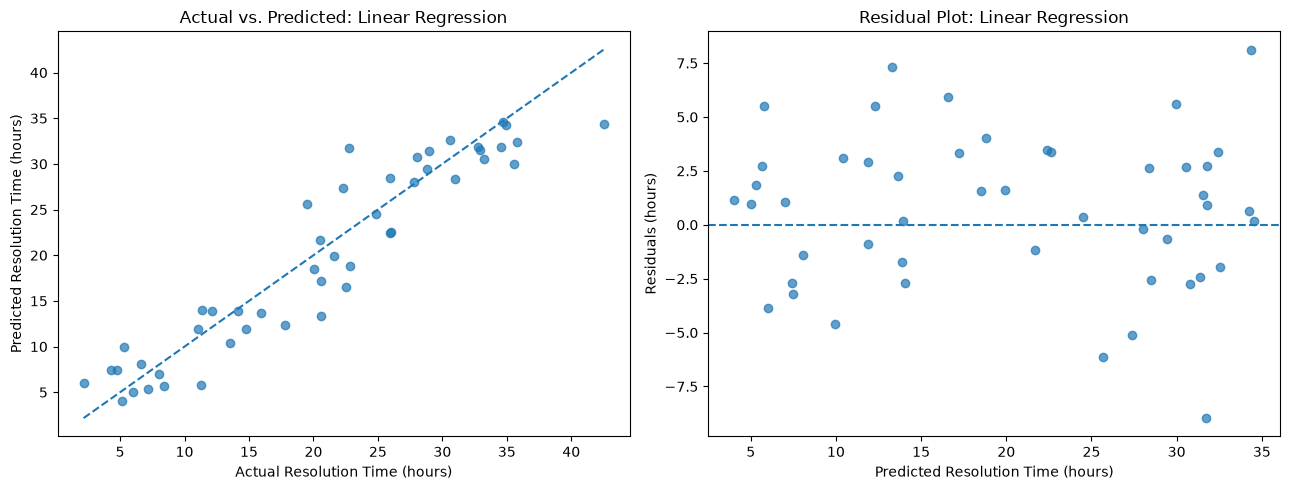

In [11]:
import matplotlib.pyplot as plt

# Train the Linear Regression model if needed
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_linear = linear_model.predict(X_test)

# Calculate residuals
residuals = y_test - y_pred_linear

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Actual vs. Predicted
axes[0].scatter(y_test, y_pred_linear, alpha=0.7)

min_value = min(y_test.min(), y_pred_linear.min())
max_value = max(y_test.max(), y_pred_linear.max())

axes[0].plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

axes[0].set_xlabel("Actual Resolution Time (hours)")
axes[0].set_ylabel("Predicted Resolution Time (hours)")
axes[0].set_title("Actual vs. Predicted: Linear Regression")

# Plot 2: Residuals
axes[1].scatter(y_pred_linear, residuals, alpha=0.7)
axes[1].axhline(y=0, linestyle="--")
axes[1].set_xlabel("Predicted Resolution Time (hours)")
axes[1].set_ylabel("Residuals (hours)")
axes[1].set_title("Residual Plot: Linear Regression")

plt.tight_layout()
plt.show()

Final Model Recommendation

Based on the test results, Linear Regression, Ridge Regression, and Lasso Regression performed best, each achieving an MAE of 2.906 hours, an RMSE of 3.572 hours, and an R² score of 0.884. Polynomial Regression with degrees 2 and 3 performed slightly worse, indicating that adding polynomial features did not improve prediction accuracy. The Dummy Regressor performed poorly compared with the other models. Therefore, Linear Regression is recommended because it provides comparable predictive accuracy with less complexity and is easier to interpret.

Analysis Questions 

10. mean baseline is used as a reference to evaluate machine learning algorithms performbetter than simple approach.It predicts the average resolution time from the training data for every ticket.

11. linear regression, Ridge Regression,and Lasso Regression has the lowest MAE AND RMSE. they performed better than the other models

12. Polynomial features didn't improve validation performace because the linear model has already captured the relationship well. The polynomial models had higher MAE and RMSE Than linear regression

13. Regularization reduces overfitting by penalizing large coefficients, helping models avoid fitting noise and generalize better to unseen data.

14. Scaling puts all features on a similar scale so that no feature dominates because of its larger numerical values. This is important for Ridge and Lasso because regularization penalizes coefficients, and scaling helps ensure the penalty affects the features more fairly.

15. One potential data leakage issue is the lines_changed and reopened features, because they may only be known after a ticket is resolved. I excluded them from the input features to prevent the model from using information that might not be available at prediction time.

16. A random split may not be appropriate because time matters, and it could mix past and future tickets between training and testing. A time-based split would better evaluate how well the model predicts resolution times for future tickets.

17. Before deploying the model, I would test it on new, unseen data, analyze residuals for patterns, and monitor prediction errors over time to ensure the model remains accurate and reliable.
